# TinyCD: change detection with a tiny network

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shresth-keshari/tinycd-demo/blob/main/notebooks/TinyCD_demo.ipynb)

**Change detection** means: given two photos of the same place taken at different times, mark the pixels that really changed
(for example a new building) and ignore the rest (lighting, seasons, shadows).

**TinyCD** (Codegoni, Lombardi & Ferrari, *Neural Computing and Applications* 35, 2023) does this with only **285,128 parameters**,
far fewer than competing models, and still matches their accuracy.

This notebook is a replication by inference: we rebuilt the network from the paper, loaded the authors' released weights
(no training), and check what it does. It runs on a free Colab CPU in about a minute. It covers:

1. Load the model and check it is the real thing
2. See it work on example image pairs
3. Look inside: the attention masks the model builds
4. Reproduce the benchmark numbers and compare with BIT and ChangeFormer
5. Try your own images

In [1]:
# Setup. On Colab this clones the repo; locally it just uses the repo you already have.
import os, sys, subprocess
if not os.path.exists("tinycd"):
    if os.path.exists("../tinycd"):
        os.chdir("..")
    else:
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/shresth-keshari/tinycd-demo.git"], check=True)
        os.chdir("tinycd-demo")
sys.path.insert(0, os.getcwd())
try:
    import torch, torchvision, PIL, matplotlib, numpy
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
print("working directory:", os.getcwd())

working directory: D:\Sem7\CE712\tinycd-demo


## 1. Load the model

`load_tinycd()` downloads the authors' checkpoint from their GitHub repository (about 1.2 MB), checks its SHA-256 fingerprint,
and loads it into our own implementation of the architecture with `strict=True`. Strict means every weight name and shape must
match exactly, so if our network differed from the authors' anywhere, loading would fail.

In [2]:
import json, time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tinycd import load_tinycd, predict_pair, overlay

net = load_tinycd()
n_params = sum(p.numel() for p in net.parameters())
print(f"Loaded. Parameters: {n_params:,}  (paper reports 285,128)")

Weights OK: D:\Sem7\CE712\tinycd-demo\weights\levir_best.pth (sha256 verified)


Loaded. Parameters: 285,128  (paper reports 285,128)


### What the parts are

TinyCD is a small "U-Net" that looks at both images at once:

| Part | Job | Parameters |
|---|---|---|
| **Backbone** (first 4 blocks of EfficientNet-B4, *shared* by both images) | Turn each image into feature maps at 3 scales | most of the model |
| **Mix** blocks | Fuse the "before" and "after" features channel by channel | tiny |
| **MAMB** (Mix + small per-pixel network) | Produce a 1-channel *attention mask* at 3 scales saying "something may have changed here" | tiny |
| **Up blocks** (decoder) | Scale back up to full size, gated by the masks | small |
| **Pixel-wise classifier** | Final change / no-change probability per pixel | tiny |

In [3]:
groups = {
    "Backbone (EfficientNet-B4, blocks 0-3)": net._backbone,
    "First Mix+mask at full resolution (256)": net._first_mix,
    "Mix / MAMB at scales 128, 64, 32": net._mixing_mask,
    "Decoder (Up blocks)": net._up,
    "Pixel-wise classifier": net._classify,
}
for name, m in groups.items():
    k = sum(p.numel() for p in m.parameters())
    print(f"{name:45s}{k:>9,}  ({100*k/n_params:4.1f}%)")

Backbone (EfficientNet-B4, blocks 0-3)         269,362  (94.5%)
First Mix+mask at full resolution (256)            162  ( 0.1%)
Mix / MAMB at scales 128, 64, 32                 3,195  ( 1.1%)
Decoder (Up blocks)                             11,734  ( 4.1%)
Pixel-wise classifier                              675  ( 0.2%)


## 2. See it work

Six example pairs from the LEVIR-CD test set (they ship with this repo). For each we show the *before* and *after* image,
the human-drawn answer (ground truth), and the changes TinyCD predicts, in red. `F1` is the usual score for this task
(1.0 is perfect; it balances missing changes against false alarms).

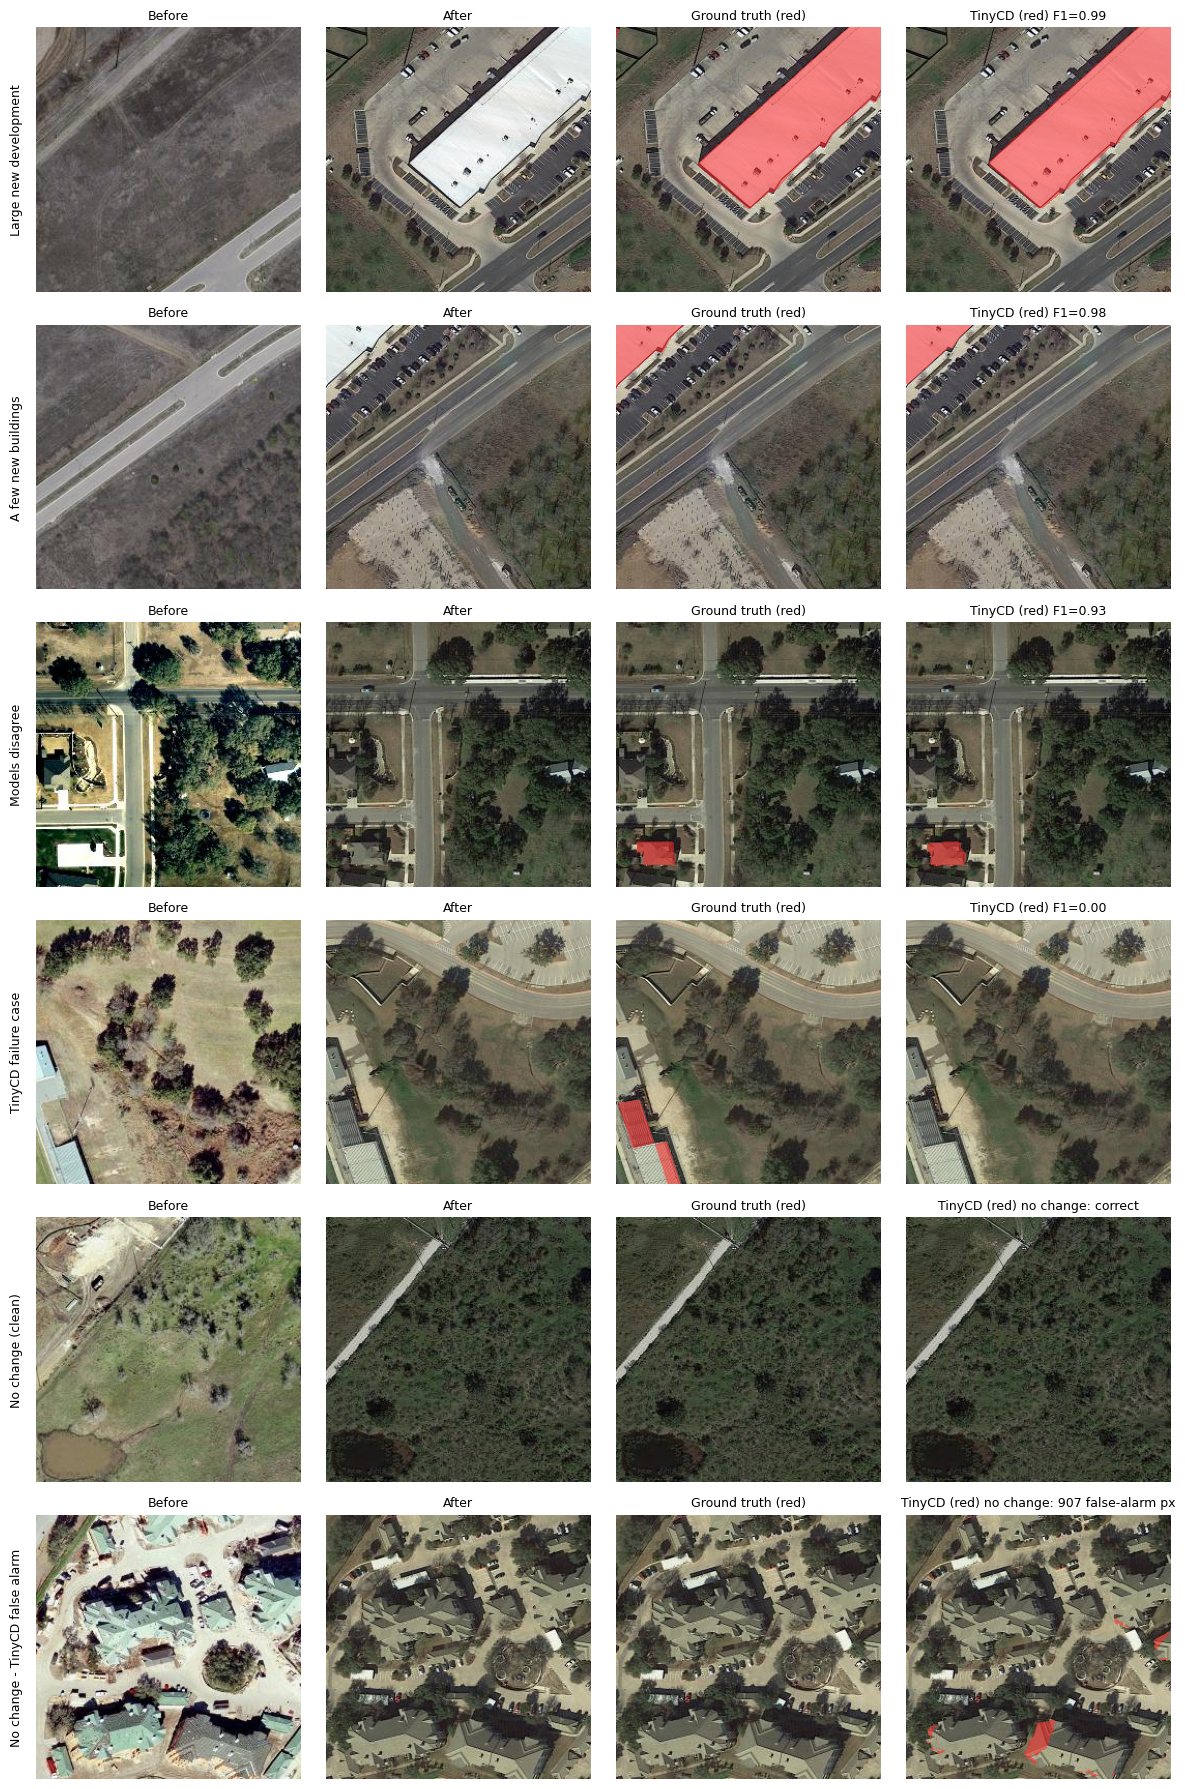

In [4]:
def f1(pred, gt):
    tp = (pred & gt).sum(); fp = (pred & ~gt).sum(); fn = (~pred & gt).sum()
    return 2 * tp / max(2 * tp + fp + fn, 1)

samples = json.load(open("docs/samples/index.json"))
fig, axes = plt.subplots(len(samples), 4, figsize=(12, 3 * len(samples)))
for row, s in zip(axes, samples):
    d = f"docs/samples/{s['dir']}/"
    a = np.array(Image.open(d + "A.png").convert("RGB")); b = np.array(Image.open(d + "B.png").convert("RGB"))
    gt = np.array(Image.open(d + "label.png")) > 127
    p = predict_pair(net, a, b)
    pred = p >= 0.5
    score = f"F1={f1(pred, gt):.2f}" if gt.any() else (f"no change: {int(pred.sum())} false-alarm px" if pred.any() else "no change: correct")
    for ax, im, t in zip(row, [a, b, overlay(b, gt.astype(float)), overlay(b, p)],
                         ["Before", "After", "Ground truth (red)", f"TinyCD (red) {score}"]):
        ax.imshow(im); ax.set_title(t, fontsize=9); ax.axis("off")
    row[0].text(-0.05, 0.5, s["title"], transform=row[0].transAxes, rotation=90, va="center", ha="right", fontsize=9)
plt.tight_layout(); plt.show()

Two of these are deliberately **failure cases** (a model that is almost perfect on most pairs still makes mistakes):
`test_19_1` (a real change it misses) and `test_19_3` (a false alarm where nothing was built).
For "no change" images there is nothing to score with F1, so we simply count false-alarm pixels.

### Threshold: how sure must the model be?
The network outputs a probability per pixel. Choosing a threshold turns it into a yes/no map. The paper uses 0.5.

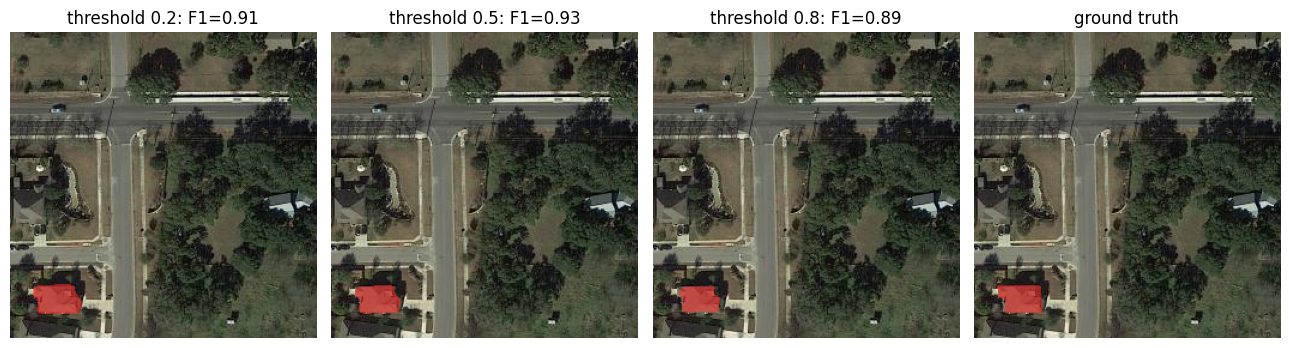

In [5]:
d = "docs/samples/test_109_13/"
a = np.array(Image.open(d + "A.png").convert("RGB")); b = np.array(Image.open(d + "B.png").convert("RGB"))
gt = np.array(Image.open(d + "label.png")) > 127
p = predict_pair(net, a, b)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, th in zip(axes, [0.2, 0.5, 0.8]):
    ax.imshow(overlay(b, p, th)); ax.set_title(f"threshold {th}: F1={f1(p >= th, gt):.2f}"); ax.axis("off")
axes[3].imshow(overlay(b, gt.astype(float))); axes[3].set_title("ground truth"); axes[3].axis("off")
plt.tight_layout(); plt.show()

## 3. Look inside: the attention masks

The paper's key idea is the **MAMB**: at three scales the network compares the two images' features and produces a one-channel
mask. The decoder *multiplies* its features by that mask, so it pays attention where the images differ.
Below, the masks for one pair (brighter = more attention). The coarse masks highlight regions, the fine one outlines edges.

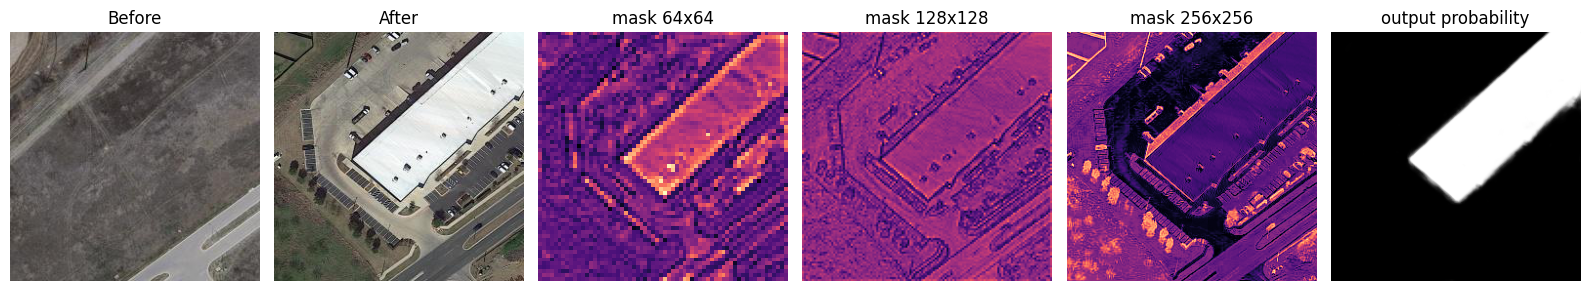

In [6]:
import torch
a = np.array(Image.open("docs/samples/test_102_9/A.png").convert("RGB"))
b = np.array(Image.open("docs/samples/test_102_9/B.png").convert("RGB"))
from tinycd.infer import MEAN, STD
ta = (torch.from_numpy(a).permute(2, 0, 1).float()[None] / 255 - MEAN) / STD
tb = (torch.from_numpy(b).permute(2, 0, 1).float()[None] / 255 - MEAN) / STD
prob, feats = net.forward_with_intermediates(ta, tb)
fig, axes = plt.subplots(1, 6, figsize=(16, 3))
axes[0].imshow(a); axes[0].set_title("Before"); axes[1].imshow(b); axes[1].set_title("After")
for ax, k in zip(axes[2:5], ["M64", "M128", "M256"]):
    m = feats[k][0, 0].numpy()
    ax.imshow(m, cmap="magma"); ax.set_title(f"mask {k[1:]}x{k[1:]}")
axes[5].imshow(prob[0, 0].numpy(), cmap="gray", vmin=0, vmax=1); axes[5].set_title("output probability")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Reproduce the benchmark numbers

We ran TinyCD, BIT and ChangeFormer (the authors' official code and weights) on **all 2,048 test pairs** of LEVIR-CD with one
shared protocol and saved the pixel counts (true/false positives and negatives). Here we recompute every metric from those
counts, so you can verify the table without the 1 GB dataset. To re-run the full evaluation yourself you need the dataset
(see the README).

In [7]:
rows = []
paper = {"tinycd": 91.05, "bit": 89.31, "changeformer": 90.40}
for key in ["tinycd", "bit", "changeformer"]:
    ev = json.load(open(f"results/eval_{key}_test.json"))
    c = ev["counts"]; tp, fp, fn, tn = c["tp"], c["fp"], c["fn"], c["tn"]
    prec, rec = tp / (tp + fp), tp / (tp + fn)
    f = 2 * prec * rec / (prec + rec); iou = tp / (tp + fp + fn)
    eff = json.load(open("results/efficiency.json"))["models"][key]
    rows.append((ev["meta"]["label"], 100 * prec, 100 * rec, 100 * f, 100 * iou, paper[key], eff["params_used"], eff["gflops"]))
print(f"{'model':16s}{'precision':>10s}{'recall':>8s}{'F1':>8s}{'IoU':>8s}{'paper F1':>10s}{'params':>13s}{'GFLOPs':>8s}")
for r in rows:
    print(f"{r[0]:16s}{r[1]:10.2f}{r[2]:8.2f}{r[3]:8.2f}{r[4]:8.2f}{r[5]:10.2f}{r[6]:13,d}{r[7]:8.2f}")

model            precision  recall      F1     IoU  paper F1       params  GFLOPs
TinyCD               92.66   89.53   91.07   83.60     91.05      285,128    1.46
BIT                  90.33   89.56   89.94   81.72     89.31    3,037,026    8.76
ChangeFormer V6      92.06   88.80   90.40   82.48     90.40   41,026,674  138.80


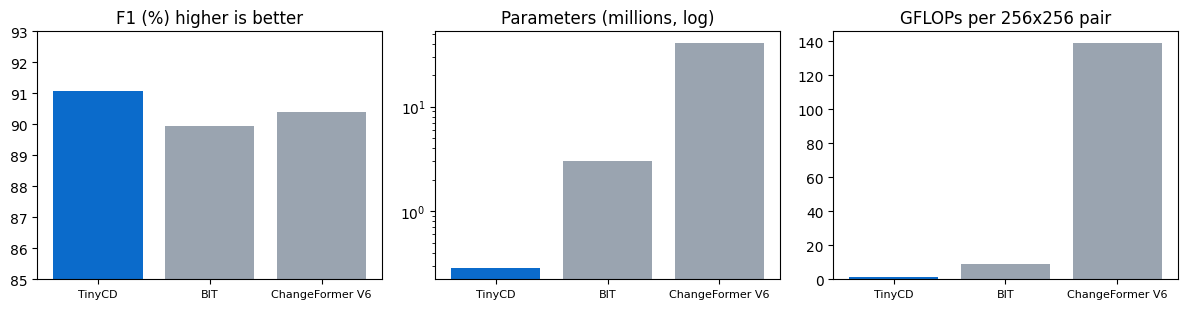

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
names = [r[0] for r in rows]; cols = ["#0b6bcb", "#9aa4b0", "#9aa4b0"]
ax[0].bar(names, [r[3] for r in rows], color=cols); ax[0].set_ylim(85, 93); ax[0].set_title("F1 (%) higher is better")
ax[1].bar(names, [r[6] / 1e6 for r in rows], color=cols); ax[1].set_yscale("log"); ax[1].set_title("Parameters (millions, log)")
ax[2].bar(names, [r[7] for r in rows], color=cols); ax[2].set_title("GFLOPs per 256x256 pair")
for a in ax: a.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

**Reading the table.** TinyCD's F1 (91.07) matches the paper's reported 91.05, which shows the architecture and weights are
reproduced correctly. TinyCD gets this with about 10x fewer parameters than BIT and 140x fewer than ChangeFormer, and about 6x
and 95x fewer operations. Our BIT number (89.94) is higher than the one in its paper (89.31); we did not find the reason, so we
report it as measured.

### Speed on this machine

In [9]:
x = torch.rand(1, 3, 256, 256)
with torch.no_grad():
    net(x, x)
    times = []
    for _ in range(10):
        t0 = time.perf_counter(); net(x, x); times.append((time.perf_counter() - t0) * 1000)
ms = sorted(times)[len(times) // 2]
print(f"Median CPU time for one 256x256 pair: {ms:.0f} ms (this machine, {torch.get_num_threads()} threads)")

Median CPU time for one 256x256 pair: 1804 ms (this machine, 8 threads)


### Architecture variants (parameter counts)
The paper tests variants (replace Mix with subtraction or concatenation, drop the masks, use a smaller backbone). We rebuild each
and count parameters. The full model, seven fusion / classifier variants and the B3 backbone match the paper's counts exactly, which confirms the architecture details. The B0-B2 backbones differ from the paper by 272 parameters (about 0.2%); we did not find the cause and report it as measured. Released weights exist only for the
full model, so we do **not** measure variant accuracy; those numbers would come from the paper only.

In [10]:
from tinycd.model import TinyCD, count_params
v = json.load(open("results/variants.json"))
print(f"{'variant':16s}{'params':>10s}{'paper':>10s}  match")
for x in v:
    pp = f"{x['paper_params']:,d}" if x["paper_params"] else "n/a"
    print(f"{x['id']:16s}{x['params']:>10,d}{pp:>10s}  {x['match'] if x['paper_params'] else '(not in paper)'}")

variant             params     paper  match
paper              285,128   285,128  True
sub_all            282,939   282,939  True
sub_skips          284,004   284,004  True
sub_bottleneck     284,063   284,063  True
cat_all            368,468   368,468  True
cat_skips          313,028   313,028  True
cat_bottleneck     340,568   340,568  True
no_classifier      282,438   282,438  True
no_skip            282,836       n/a  (not in paper)
b0                  79,208    79,480  False
b1                 121,820   122,092  False
b2                 147,768   148,040  False
b3                 178,716   178,716  True


## 5. Try your own images

Upload a *before* and an *after* aerial image of the same size (ideally about 0.5 m per pixel, like the training data; larger
images are processed in 256x256 tiles). On Colab run the next cell; locally, set the two file paths.

In [11]:
try:
    from google.colab import files
    print("Choose the BEFORE image, then the AFTER image:")
    up = files.upload(); path_a, path_b = list(up.keys())[:2]
except ImportError:
    path_a = path_b = None          # <- set these to your own files when running locally, e.g. "before.png"

if path_a:
    a = np.array(Image.open(path_a).convert("RGB")); b = np.array(Image.open(path_b).convert("RGB"))
    p = predict_pair(net, a, b)
    fig, ax = plt.subplots(1, 3, figsize=(14, 5))
    for x, im, t in zip(ax, [a, b, overlay(b, p)], ["Before", "After", "TinyCD change (red)"]):
        x.imshow(im); x.set_title(t); x.axis("off")
    plt.show()
else:
    print("No images given; skipping.")

No images given; skipping.


---
**Notes.** The model was trained on 256x256 aerial crops at 0.5 m per pixel (LEVIR-CD: new or demolished buildings).
It will not generalise to arbitrary scenes (very different resolution, satellite sensor or kinds of change).
No training was done in this project: all results use the authors' released weights.
Also available: the live in-browser demo (`docs/` folder, GitHub Pages) which runs this same model through ONNX.